# 01 - Análisis exploratorio de datos (EDA)
**Proyecto:** Prueba de Suficiencia - Administración de Datos
**Dataset:** Home Loan Approval (Kaggle, rishikeshkonapure/home-loan-approval)

Cada registro es una **solicitud de préstamo de vivienda**. La variable objetivo es `Loan_Status`
(Y = aprobado, N = rechazado). Es un problema de **clasificación binaria**.

En este notebook solo exploro los datos. Las decisiones de limpieza se aplican en el notebook 02 (ETL).

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RUTA_DATOS = "../data/loan_sanction_train.csv"
RUTA_FIGURAS = "../reports/figuras/"
os.makedirs(RUTA_FIGURAS, exist_ok=True)

## 1. Carga inicial del dataset
Se usa solo `loan_sanction_train.csv` porque `loan_sanction_test.csv` no trae la variable objetivo
(no sirve para entrenar ni para evaluar).

In [2]:
df = pd.read_csv(RUTA_DATOS)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2. Dimensiones y tipos de datos

In [3]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
df.info()

Filas: 614
Columnas: 13
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


Observaciones:
- `Dependents` viene como texto porque tiene el valor `"3+"`.
- `Credit_History` es numérica pero en realidad es una variable binaria (1 = cumple, 0 = no cumple).
- `Loan_Amount_Term` es numérica pero solo toma pocos valores (plazos en meses).
- `Loan_ID` es solo un identificador, no aporta para predecir.

In [4]:
# ¿hay IDs repetidos o filas duplicadas?
print("IDs duplicados:", df["Loan_ID"].duplicated().sum())
print("Filas duplicadas:", df.drop(columns="Loan_ID").duplicated().sum())

IDs duplicados: 0
Filas duplicadas: 0


## 3. Variables categóricas y numéricas

In [5]:
categoricas = ["Gender", "Married", "Dependents", "Education", "Self_Employed",
               "Property_Area", "Credit_History"]
numericas = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
objetivo = "Loan_Status"

print("Categóricas:", categoricas)
print("Numéricas:", numericas)

for col in categoricas:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Categóricas: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Credit_History']
Numéricas: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

Gender:
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64

Married:
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Dependents:
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

Education:
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

Self_Employed:
Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64

Property_Area:
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

Credit_History:
Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64


## 4. Valores nulos

In [6]:
nulos = df.isna().sum().to_frame("nulos")
nulos["porcentaje"] = (nulos["nulos"] / len(df) * 100).round(2)
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
nulos

,nulos,porcentaje
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49


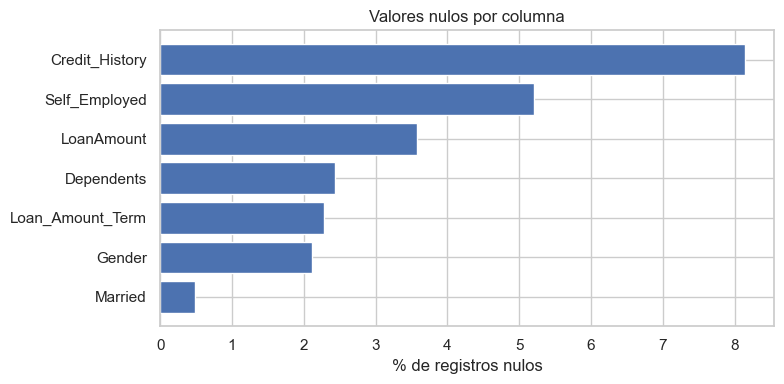

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(nulos.index, nulos["porcentaje"], color="#4C72B0")
ax.set_xlabel("% de registros nulos")
ax.set_title("Valores nulos por columna")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "nulos.png", dpi=120)
plt.show()

`Credit_History` es la columna con más nulos (~8%) y además es la más importante (se ve abajo).
Hay que revisar si los nulos se comportan distinto antes de decidir cómo rellenarlos.

## 5. Distribución de la variable objetivo y balance de clases

Loan_Status
Y    422
N    192
Name: count, dtype: int64
Loan_Status
Y    68.7
N    31.3
Name: proportion, dtype: float64


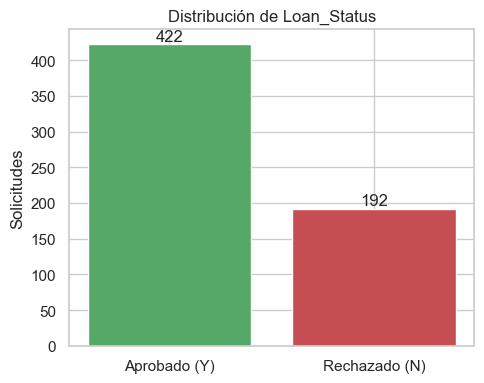

In [8]:
conteo = df[objetivo].value_counts()
print(conteo)
print((df[objetivo].value_counts(normalize=True) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Aprobado (Y)", "Rechazado (N)"], [conteo["Y"], conteo["N"]], color=["#55A868", "#C44E52"])
for i, v in enumerate([conteo["Y"], conteo["N"]]):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_title("Distribución de Loan_Status")
ax.set_ylabel("Solicitudes")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "objetivo.png", dpi=120)
plt.show()

Hay un **desbalance moderado**: ~69% aprobados vs ~31% rechazados.
No es extremo, pero un modelo que diga "aprobado" a todo ya tendría 69% de accuracy.
Por eso:
- La separación train/test va a ser **estratificada**.
- Se va a comparar con `class_weight="balanced"` y se va a mirar más allá de la accuracy (precision, recall, F1, ROC-AUC).

## 6. Estadísticas descriptivas

In [9]:
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0


In [10]:
# asimetría: valores altos indican colas largas (outliers)
df[numericas].skew().round(2)

ApplicantIncome      6.54
CoapplicantIncome    7.49
LoanAmount           2.68
Loan_Amount_Term    -2.36
dtype: float64

Los ingresos y el monto del préstamo tienen **mucha asimetría** (colas largas a la derecha).
La media de `ApplicantIncome` (~5,400) es bastante mayor que la mediana (~3,800).

## 7. Visualizaciones

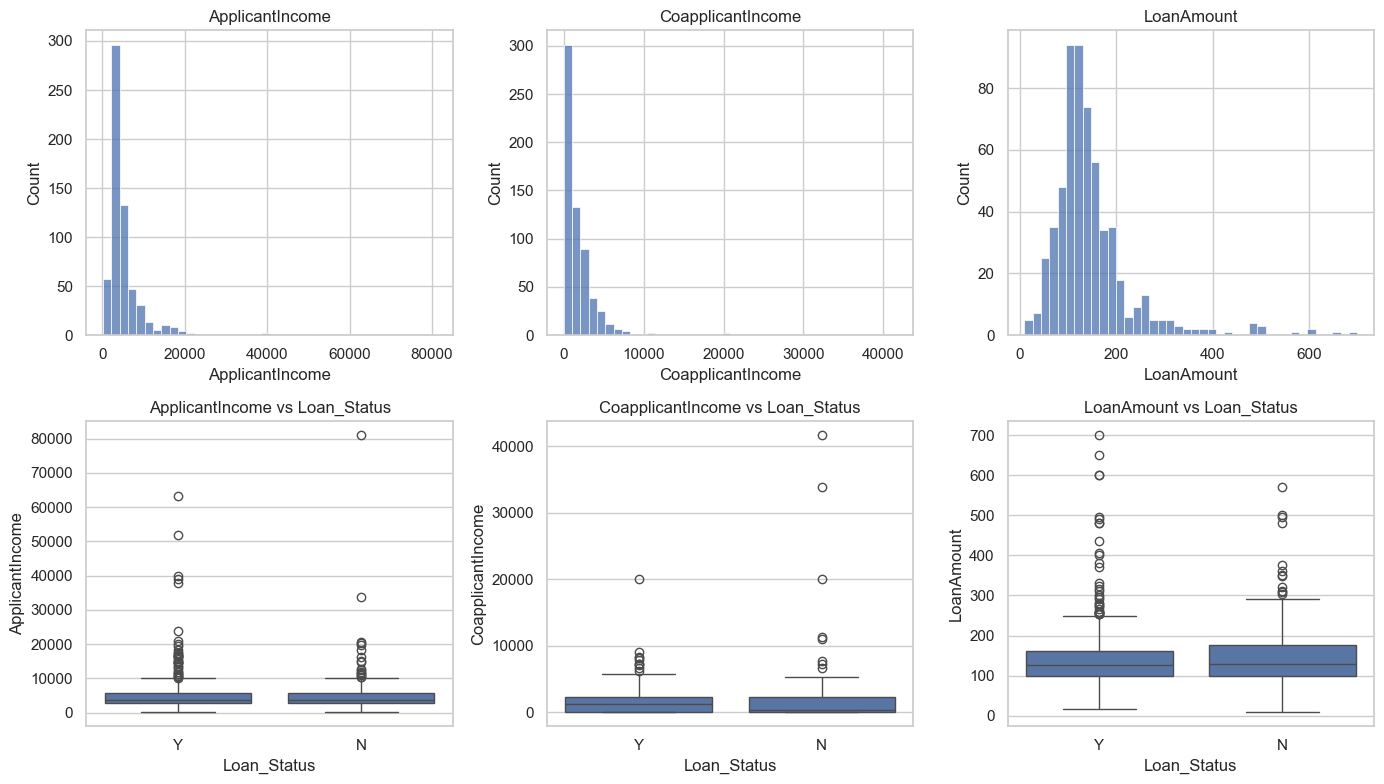

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="#4C72B0")
    ax.set_title(f"{col}")
for ax, col in zip(axes.flat[3:], ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.boxplot(x=df[objetivo], y=df[col], ax=ax, order=["Y", "N"])
    ax.set_title(f"{col} vs Loan_Status")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "numericas.png", dpi=120)
plt.show()

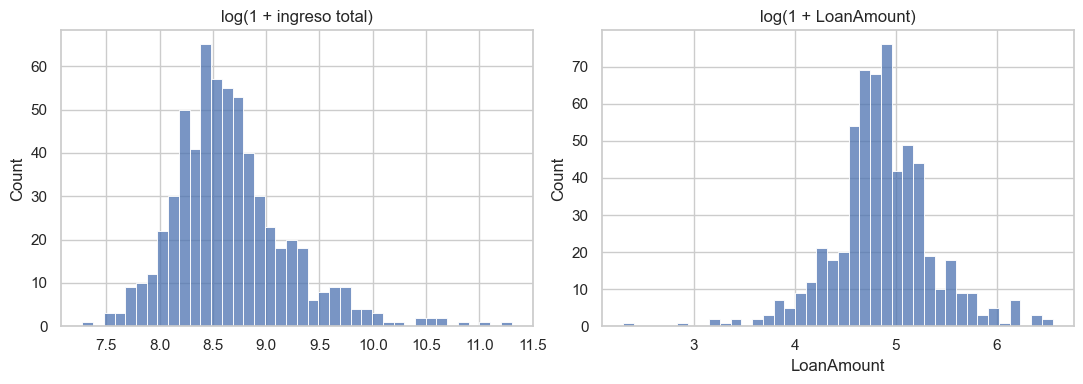

In [12]:
# como hay colas largas, se ve mejor en escala logarítmica
ingreso_total = df["ApplicantIncome"] + df["CoapplicantIncome"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(np.log1p(ingreso_total), bins=40, ax=axes[0])
axes[0].set_title("log(1 + ingreso total)")
sns.histplot(np.log1p(df["LoanAmount"].dropna()), bins=40, ax=axes[1])
axes[1].set_title("log(1 + LoanAmount)")
plt.tight_layout()
plt.show()

Con logaritmo las distribuciones quedan mucho más simétricas. Esto se usa en el ETL.

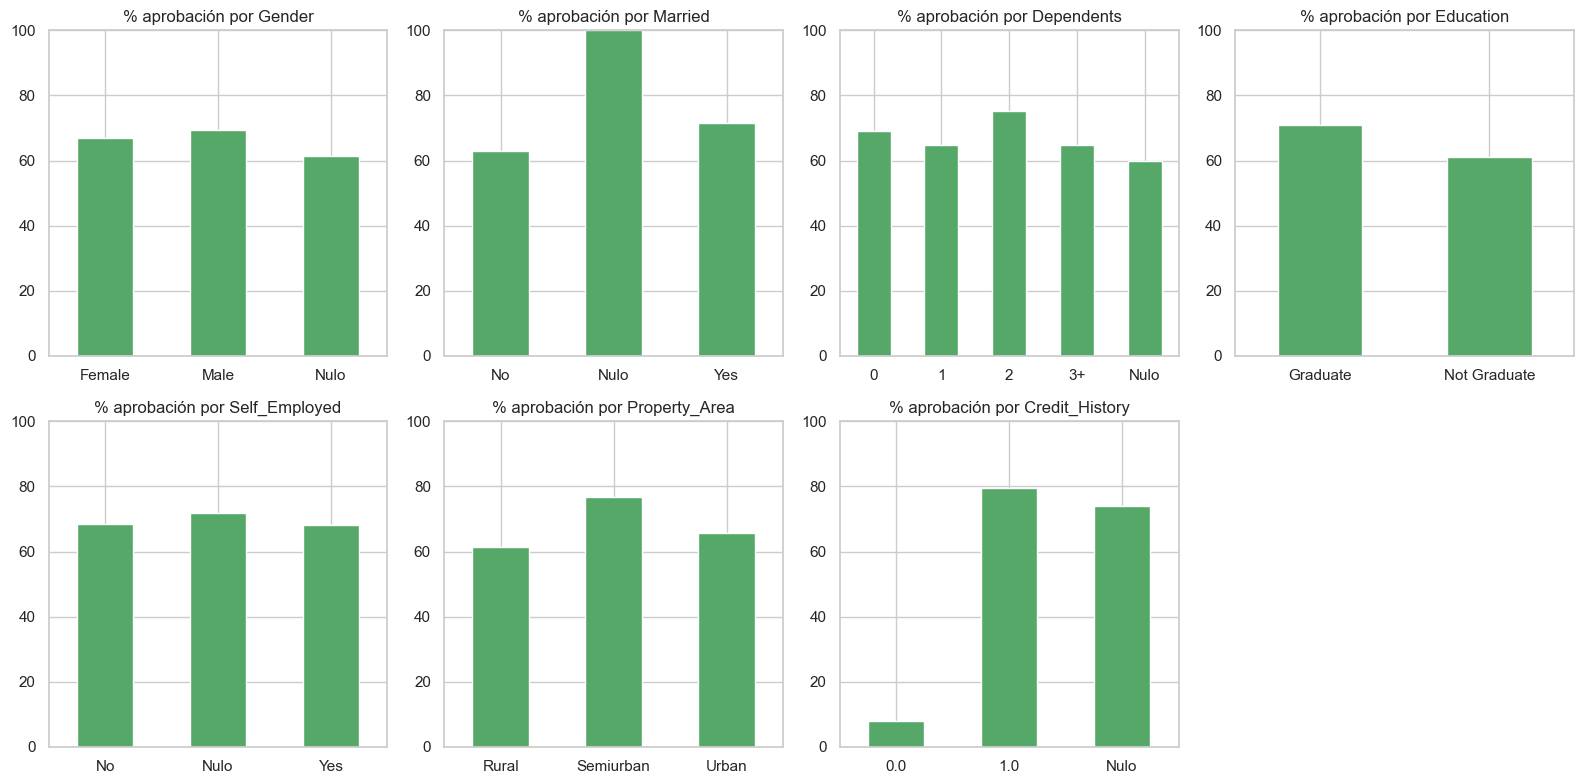

In [13]:
# tasa de aprobación por cada variable categórica
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, categoricas):
    tasa = (df.assign(aprobado=(df[objetivo] == "Y"))
              .groupby(df[col].fillna("Nulo").astype(str))["aprobado"].mean() * 100)
    tasa.plot(kind="bar", ax=ax, color="#55A868")
    ax.set_title(f"% aprobación por {col}")
    ax.set_ylim(0, 100)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "categoricas.png", dpi=120)
plt.show()

Lo más fuerte es **`Credit_History`**:

In [14]:
pd.crosstab(df["Credit_History"].fillna(-1), df[objetivo], normalize="index").round(3) * 100

Loan_Status,N,Y
Credit_History,,
-1.0,26.0,74.0
0.0,92.1,7.9
1.0,20.4,79.6


- Con historial = 0 casi nadie es aprobado (~8%).
- Con historial = 1 se aprueba ~80%.
- Los **nulos** se aprueban ~74%, que **no** se parece a ninguno de los dos grupos.

**Decisión:** no rellenar `Credit_History` con la moda (eso diría que todos los nulos "cumplen").
En el ETL se va a tratar el nulo como su propia categoría ("sin historial").

También se ve que `Property_Area = Semiurban` y estar casado tienen algo más de aprobación.
`Gender` y `Self_Employed` casi no cambian la tasa.

## 8. Correlaciones y relaciones entre variables

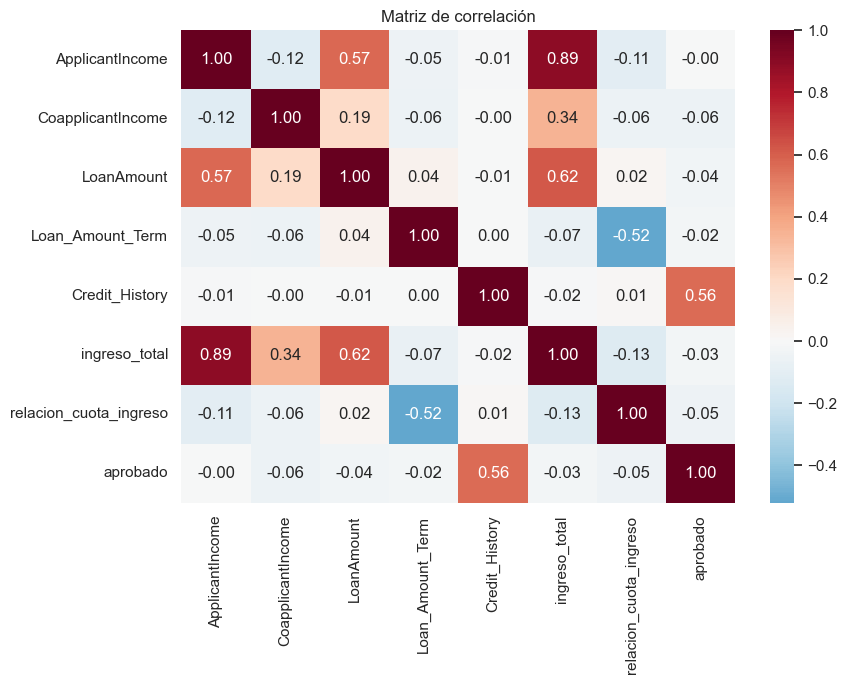

In [15]:
aux = df.copy()
aux["aprobado"] = (aux[objetivo] == "Y").astype(int)
aux["ingreso_total"] = aux["ApplicantIncome"] + aux["CoapplicantIncome"]
aux["cuota_aprox"] = aux["LoanAmount"] / aux["Loan_Amount_Term"]
aux["relacion_cuota_ingreso"] = aux["cuota_aprox"] * 1000 / aux["ingreso_total"]

cols_corr = numericas + ["Credit_History", "ingreso_total", "relacion_cuota_ingreso", "aprobado"]
corr = aux[cols_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "correlacion.png", dpi=120)
plt.show()

- `Credit_History` es la única variable con correlación clara con la aprobación (~0.56).
- `LoanAmount` se correlaciona con los ingresos (a más ingreso, piden más).
- Los ingresos solos casi no se correlacionan con la aprobación. Por eso pruebo una variable
  derivada (`relacion_cuota_ingreso`) que mide si la cuota es pesada para el ingreso.

## 9. Problemas de calidad de datos encontrados

| Problema | Columnas | Qué se hará en el ETL |
|---|---|---|
| Valores nulos | 7 columnas (Credit_History 8%, Self_Employed 5%, LoanAmount 4%...) | Imputar con estadísticas **solo del set de entrenamiento** |
| Nulos con comportamiento propio | Credit_History | Categoría aparte "sin historial" (valor -1 + bandera) |
| Tipo incorrecto | Dependents ("3+") | Convertir a entero (3+ → 3) |
| Colas largas / outliers | Ingresos, LoanAmount | Transformación logarítmica (no se eliminan: son clientes reales) |
| Columna sin valor predictivo | Loan_ID | Se conserva como llave en la BD pero no entra al modelo |
| Desbalance moderado | Loan_Status | Split estratificado + `class_weight` + métricas más allá de accuracy |
| Test sin objetivo | loan_sanction_test.csv | No se usa |

## 10. Conclusiones del EDA
1. El dataset es pequeño (614 solicitudes, 13 columnas), así que conviene usar **validación cruzada**.
2. `Credit_History` es el predictor dominante; hay que tratar bien sus nulos.
3. Las variables de dinero necesitan transformación logarítmica por su asimetría.
4. Vale la pena crear variables derivadas (ingreso total, cuota aproximada, relación cuota/ingreso).
5. El desbalance 69/31 obliga a mirar precision y recall, sobre todo de los **rechazados**:
   para el banco, aprobar a alguien que no debía (falso positivo) es el error más caro.